Samajhna pehle:

- Data drift: model jo inputs dekh raha hai, wo training ke inputs se alag ho gaye. Concept drift: inputs se churn ka rishta badal gaya. Drift ka matlab “performance gira” nahi hota. Performance ke liye labels chahiye, aur tumhare project mein label 90 din baad aata hai (Day 94). Isliye drift monitoring woh early warning hai jo labels aane se pehle mil sakti hai.
- Tests: PSI (Population Stability Index), KS test, chi-square, Wasserstein distance. PSI ke rules of thumb: 0.1 se neeche stable, 0.1 se 0.25 “watch”, 0.25 se upar “alert”. Yeh credit-scoring ki convention hai, statistical law nahi.
- Bade sample ka jaal (Day 44 yaad karo): KS ya chi-square ka p-value hazaaron rows par bahut chhote fark ko bhi “significant” bata deta hai. Isliye p-value ke saath effect size (PSI, Wasserstein) dekhna zaroori hai.
- Multiple testing: 19 features par alpha 0.05 ka matlab chance se ~1 galat alarm. Aur tumhare features aapas mein correlated hain, to “10 features drift hue” ka matlab 10 alag kahaniyan nahi hoti.
Drift by construction: Tumhare features cutoff ke relative hain, to snapshot aage badhne par Tenure apne aap badhta hai (ek hi customer ka Tenure do snapshots mein ~182 din alag hoga). Aaj ise khud verify karenge.

Rules:

- Evidently ko alag virtual environment mein rakhenge (MLflow wali seekh). Poora drift logic hum apne drift.py mein likhenge (numpy, pandas, scipy), taaki Evidently na chale tab bhi kaam na ruke. Evidently sirf HTML report aur cross-check ke liye hai.
- Evidently ka API versions ke beech bahut badla hai, aur main yeh code tumhare version par chala nahi sakta. Isliye script teen API tareeke try karti hai. Agar import error aaye, to pip show evidently ka version aur error mujhe bhej dena.
- Monitoring sirf record aur alert karti hai. Retrain/promote ka faisla Day 94 ke gates se hi hoga.

1: Setup aur snapshot loader


In [1]:
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')


def find_root(start=None) -> Path:
    p = Path(start or Path.cwd()).resolve()
    for d in [p, *p.parents]:
        if (d / 'src').is_dir() and (d / 'requirements.txt').exists():
            return d
    raise FileNotFoundError('repo root nahi mila')


ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.app import service  # noqa: E402
from src.features.build_features import NUM_V2, make_xy  # noqa: E402
from src.monitoring.drift import PSI_ALERT, PSI_WATCH, drift_policy, drift_report, psi  # noqa: E402


def load_snapshot(tag: str) -> pd.DataFrame:
    runs = sorted((ROOT / 'pipeline_runs').glob(f'asof-{tag}_h90_*'), key=lambda p: p.stat().st_mtime)
    if not runs:
        raise FileNotFoundError(f'pipeline_runs mein asof-{tag}_h90_* nahi mila. Pehle run_pipeline --execute chalao.')
    feat = pd.read_csv(runs[-1] / 'features.csv')
    sp = pd.read_csv(runs[-1] / 'split.csv')
    print(f'{tag}: {runs[-1].name} | customers {len(feat):,}')
    return feat.merge(sp, on='Customer ID')


latest = load_snapshot('latest')
old = load_snapshot('2011-06-10')

latest: asof-latest_h90_32569a66 | customers 5,283
2011-06-10: asof-2011-06-10_h90_32569a66 | customers 4,608


2: A/A test (detector shaanti se rehna chahiye)

In [2]:
ref_aa = latest[latest['split'] == 'train']
cur_aa = latest[latest['split'] == 'holdout']          # wahi snapshot, random split: asli drift hona hi nahi chahiye
aa = drift_report(ref_aa, cur_aa, NUM_V2)
print(aa[['feature', 'psi', 'test', 'p_value', 'status']].round(4).to_string(index=False))
print(aa['status'].value_counts().to_dict())
print('features with p < 0.05 by chance:', int((aa['p_value'] < 0.05).sum()), 'of', len(aa))

           feature    psi test  p_value status
    UniqueProducts 0.0206   ks   0.2219     ok
      Monetary_log 0.0143   ks   0.1557     ok
        AvgGapDays 0.0137   ks   0.3889     ok
 MaxOrderValue_log 0.0136   ks   0.2350     ok
    OrdersPerMonth 0.0136   ks   0.8998     ok
      OverdueRatio 0.0121   ks   0.6550     ok
        OrderTrend 0.0104   ks   0.9999     ok
  Spend_last90_log 0.0103   ks   0.9962     ok
     Orders_prev90 0.0090   ks   0.7339     ok
  AvgUnitsPerOrder 0.0071   ks   0.6259     ok
RunRateValue90_log 0.0071   ks   0.5309     ok
     AvgOrderValue 0.0070   ks   0.5308     ok
            Tenure 0.0068   ks   0.9278     ok
  AvgLinesPerOrder 0.0063   ks   0.5990     ok
       LastGapDays 0.0054   ks   0.5616     ok
     Orders_last90 0.0053   ks   1.0000     ok
         Frequency 0.0053   ks   0.9951     ok
           Recency 0.0052   ks   0.7004     ok
       SingleOrder 0.0001 chi2   0.7764     ok
{'ok': 19}
features with p < 0.05 by chance: 0 of 19


Kya dikhna chahiye: sab features PSI se ok. Lekin p < 0.05 wale features ek-do aa sakte hain (alpha ka chance wala hissa), aur correlated features ek saath aa sakte hain. Yeh dikhata hai ki sirf p-value par alarm lagana kitna shor machata.

3: Snapshot comparison (June 2011 vs Dec 2011)

           feature   psi test  stat  wasserstein_sd  ref_mean  cur_mean status
            Tenure 1.104   ks 0.512           0.992   298.409   431.827  alert
        OrderTrend 0.414   ks 0.286           0.342    -0.811    -0.018  alert
           Recency 0.353   ks 0.228           0.573   141.482   207.422  alert
     Orders_prev90 0.262   ks 0.247           0.233     1.464     0.767  alert
    OrdersPerMonth 0.113   ks 0.155           0.121     0.486     0.410  watch
RunRateValue90_log 0.061   ks 0.112           0.225     5.606     5.331     ok
       LastGapDays 0.047   ks 0.066           0.238    51.288    68.702     ok
        AvgGapDays 0.033   ks 0.077           0.206    49.534    62.693     ok
      OverdueRatio 0.028   ks 0.041           0.080     5.850     8.538     ok
         Frequency 0.018   ks 0.046           0.099     4.838     5.744     ok
     Orders_last90 0.009   ks 0.029           0.065     0.652     0.749     ok
      Monetary_log 0.007   ks 0.031           0.071 

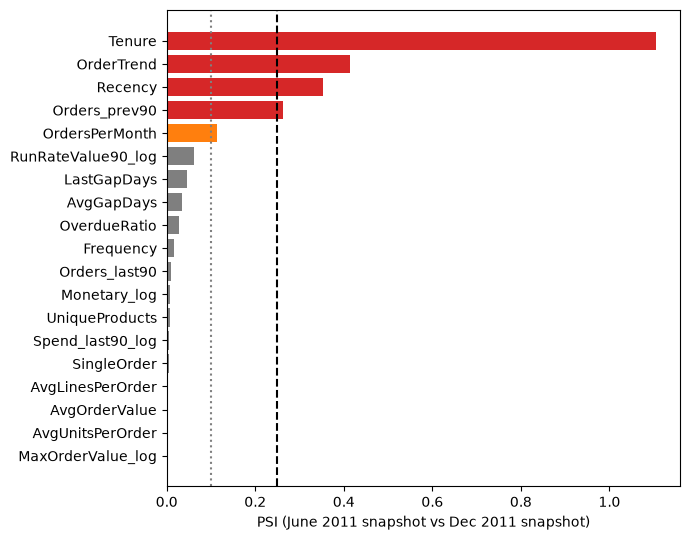

In [3]:
ab = drift_report(old, latest, NUM_V2)
print(ab[['feature', 'psi', 'test', 'stat', 'wasserstein_sd', 'ref_mean', 'cur_mean', 'status']].round(3).to_string(index=False))
print(ab['status'].value_counts().to_dict())

d = ab.sort_values('psi')
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(d['feature'], d['psi'],
        color=['#d62728' if v > PSI_ALERT else '#ff7f0e' if v > PSI_WATCH else '#7f7f7f' for v in d['psi']])
ax.axvline(PSI_WATCH, linestyle=':', color='gray')
ax.axvline(PSI_ALERT, linestyle='--', color='black')
ax.set_xlabel('PSI (June 2011 snapshot vs Dec 2011 snapshot)')
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'drift_psi_day95.png', dpi=150)
plt.show()

4: Kya yeh “asli” drift hai ya time guzarne ka asar? (Tenure ka saboot)

In [4]:
m = old.merge(latest, on='Customer ID', suffixes=('_old', '_new'))
print('customers in both snapshots:', len(m))
print((m['Tenure_new'] - m['Tenure_old']).value_counts().head(5))
print('Recency, jinhone beech mein koi order nahi kiya:', (m['Recency_new'] - m['Recency_old']).describe().round(1).to_dict())

customers in both snapshots: 4608
182    2518
183    2090
Name: count, dtype: int64
Recency, jinhone beech mein koi order nahi kiya: {'count': 4608.0, 'mean': 86.3, 'std': 120.5, 'min': -450.0, '25%': -5.0, '50%': 182.0, '75%': 182.0, 'max': 183.0}


Ek hi customer ka Tenure almost hamesha 182 ya 183 se badhega, kyunki dono cutoffs ke beech yahi fark hai. Matlab Tenure ka drift pakka “by construction” hai, aur isse alarm nahi lagana chahiye. Recency aur Frequency mein bhi time ka asar milta hai. Is cell ka jawab apni notebook mein 3 lines mein likho: kaunse features ka drift “bas waqt guzarne” se hai, aur kaunse ka asli behaviour badalne se ho sakta hai.

 5: Stress test (detector kitna chhota fark pakadta hai?)

Champion sirf latest snapshot ke train rows par seekha hai, isliye yahan holdout rows use kar rahe hain (parity check ne confirm kiya ki yeh wahi customers hain jo app mein test hain).

In [5]:
model, manifest = service.load_artifacts()
THR = manifest['threshold']


def scores(df: pd.DataFrame) -> np.ndarray:
    X = make_xy(df, NUM_V2).astype(float)[manifest['features']]
    return model.predict_proba(X)[:, 1]


def shift_recency(df: pd.DataFrame, days: int) -> pd.DataFrame:
    out = df.copy()
    out['Recency'] = np.minimum(out['Recency'] + days, out['Tenure'])
    out['OverdueRatio'] = np.where(out['SingleOrder'] == 1, 0.0,
                                   out['Recency'] / np.maximum(out['AvgGapDays'], 1.0))
    return out


hold = latest[latest['split'] == 'holdout'].sample(frac=1.0, random_state=0).reset_index(drop=True)
half = len(hold) // 2
ref_h, cur_h = hold.iloc[:half], hold.iloc[half:]
s_ref = scores(ref_h)
print(f'reference alert rate: {(s_ref >= THR).mean():.1%}')

rows = []
for days in [0, 15, 30, 60]:
    cur_s = shift_recency(cur_h, days)
    rep = drift_report(ref_h, cur_s, NUM_V2).set_index('feature')
    s_cur = scores(cur_s)
    rows.append({'recency_shift_days': days,
                 'psi_Recency': rep.loc['Recency', 'psi'],
                 'psi_OverdueRatio': rep.loc['OverdueRatio', 'psi'],
                 'score_psi': psi(s_ref, s_cur),
                 'alert_rate': float((s_cur >= THR).mean())})
stress = pd.DataFrame(rows).round(3)
print(stress.to_string(index=False))

reference alert rate: 96.8%
 recency_shift_days  psi_Recency  psi_OverdueRatio  score_psi  alert_rate
                  0        0.009             0.021      0.007       0.960
                 15        0.304             0.096      0.015       0.968
                 30        0.412             0.210      0.020       0.987
                 60        0.586             0.533      0.020       1.000


Kaise padho: 0 din wali row A/A hai (sab shaant). Ye dekho ki kitne din ke shift par Recency ka PSI “alert” hota hai, aur kya model ka score PSI aur alert rate bhi hilte hain. Alert rate ek business-friendly monitor hai: usse seedha pata chalta hai ki campaign ki list kitni badh jaayegi. Yeh ek synthetic stress test hai, asli scenario nahi.

 6: Alert policy aur save

In [6]:
imp = pd.read_csv(ROOT / 'reports' / 'shap_importance_day85b.csv', index_col=0)
KEY = [f for f in imp['mean_abs_shap'].sort_values(ascending=False).index[:8] if f != 'Tenure']   # Tenure: by construction
print('Key features:', KEY)

for name, rep in [('A/A (same snapshot)', aa), ('Jun -> Dec 2011', ab)]:
    print(name, '->', drift_policy(rep, KEY))
for _, r in stress.iterrows():
    print(f"stress +{int(r['recency_shift_days'])}d ->", drift_policy(
        drift_report(ref_h, shift_recency(cur_h, int(r['recency_shift_days'])), NUM_V2), KEY, score_psi=r['score_psi']))

ab.round(4).to_csv(ROOT / 'reports' / 'drift_snapshot_comparison_day95.csv', index=False)
stress.to_csv(ROOT / 'reports' / 'drift_stress_day95.csv', index=False)

Key features: ['OrdersPerMonth', 'Recency', 'UniqueProducts', 'RunRateValue90_log', 'Orders_prev90', 'Spend_last90_log', 'OverdueRatio', 'Monetary_log']
A/A (same snapshot) -> {'level': 'ok', 'reasons': []}
Jun -> Dec 2011 -> {'level': 'alert', 'reasons': ['2 key features in alert']}
stress +0d -> {'level': 'ok', 'reasons': []}
stress +15d -> {'level': 'watch', 'reasons': []}
stress +30d -> {'level': 'watch', 'reasons': []}
stress +60d -> {'level': 'alert', 'reasons': ['2 key features in alert']}


 7: Evidently ke liye do CSV (alag env ke liye)

In [7]:
(ROOT / 'scratch').mkdir(exist_ok=True)
old[NUM_V2].to_csv(ROOT / 'scratch' / '_drift_ref.csv', index=False)
latest[NUM_V2].to_csv(ROOT / 'scratch' / '_drift_cur.csv', index=False)

HTML report mein kya dekhna hai:

1. Kaunse columns “drifted” dikhaye gaye, aur tumhare PSI table (Cell 3) se kitna milte hain?
2. Har column ke liye kaunsa stat-test laga (report ka legend dekho). Evidently sample size aur column type ke hisaab se test chunta hai, aur uski default thresholds aur “dataset drift” ka rule (aksar aadhe columns drift hone par) bhi alag hain.
3. Kya Evidently Tenure jaise by-construction drift ko bhi alarm bana raha hai? Wahi dikhata hai ki tool ko domain knowledge nahi hota.